### **Diabetes Dataset — Exploratory Data Analysis**
Pima Indians Diabetes Dataset (768 records, 8 features + Outcome)

# LOAD DATA

In [1]:
import numpy as np
import pandas as pd
df = pd.read_csv('C:/Users/HP/Downloads/diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [2]:
print("Shape:", df.shape)

Shape: (768, 9)


- Small-to-medium dataset — good for stats, but sensitive to outliers.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


- No NaNs reported — but this is misleading, since missing values are hidden as 0s, not NaNs.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


- Zero minimums = impossible values → hidden missing data.
- Insulin is highly skewed with outliers.
- Average patient is obese (BMI ~32) and ~33 years old.
- ~35% of patients have diabetes.

In [5]:
print('Total patients:', len(df))

Total patients: 768


- Tells you the total number of patient records in the dataset.
- Confirms the dataset size you're working with — 768 rows to analyze.

In [6]:
df.head() #shows the first 5 rows

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


- Quick look at what the data looks like at the top.

In [7]:
df.isnull().sum() #checks missing values per column

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

- No official NaNs — but remember, missing data is hidden as 0s here instead

In [8]:
df["Outcome"].value_counts()  #counts diabetic vs non-diabetic

Outcome
0    500
1    268
Name: count, dtype: int64

- More non-diabetic patients than diabetic ones in this dataset.

In [9]:
df.corr()["Outcome"]  #shows which features relate most to diabetes

Pregnancies                 0.221898
Glucose                     0.466581
BloodPressure               0.065068
SkinThickness               0.074752
Insulin                     0.130548
BMI                         0.292695
DiabetesPedigreeFunction    0.173844
Age                         0.238356
Outcome                     1.000000
Name: Outcome, dtype: float64

- Glucose has the strongest connection to diabetes out of all features.

In [13]:
df.nunique() #counts unique values in each column

Pregnancies                  17
Glucose                     136
BloodPressure                47
SkinThickness                51
Insulin                     186
BMI                         248
DiabetesPedigreeFunction    517
Age                          52
Outcome                       2
dtype: int64

- Helps you tell which columns are categories (like Outcome) vs. continuous measurements (like Glucose, BMI).

# GRAPH

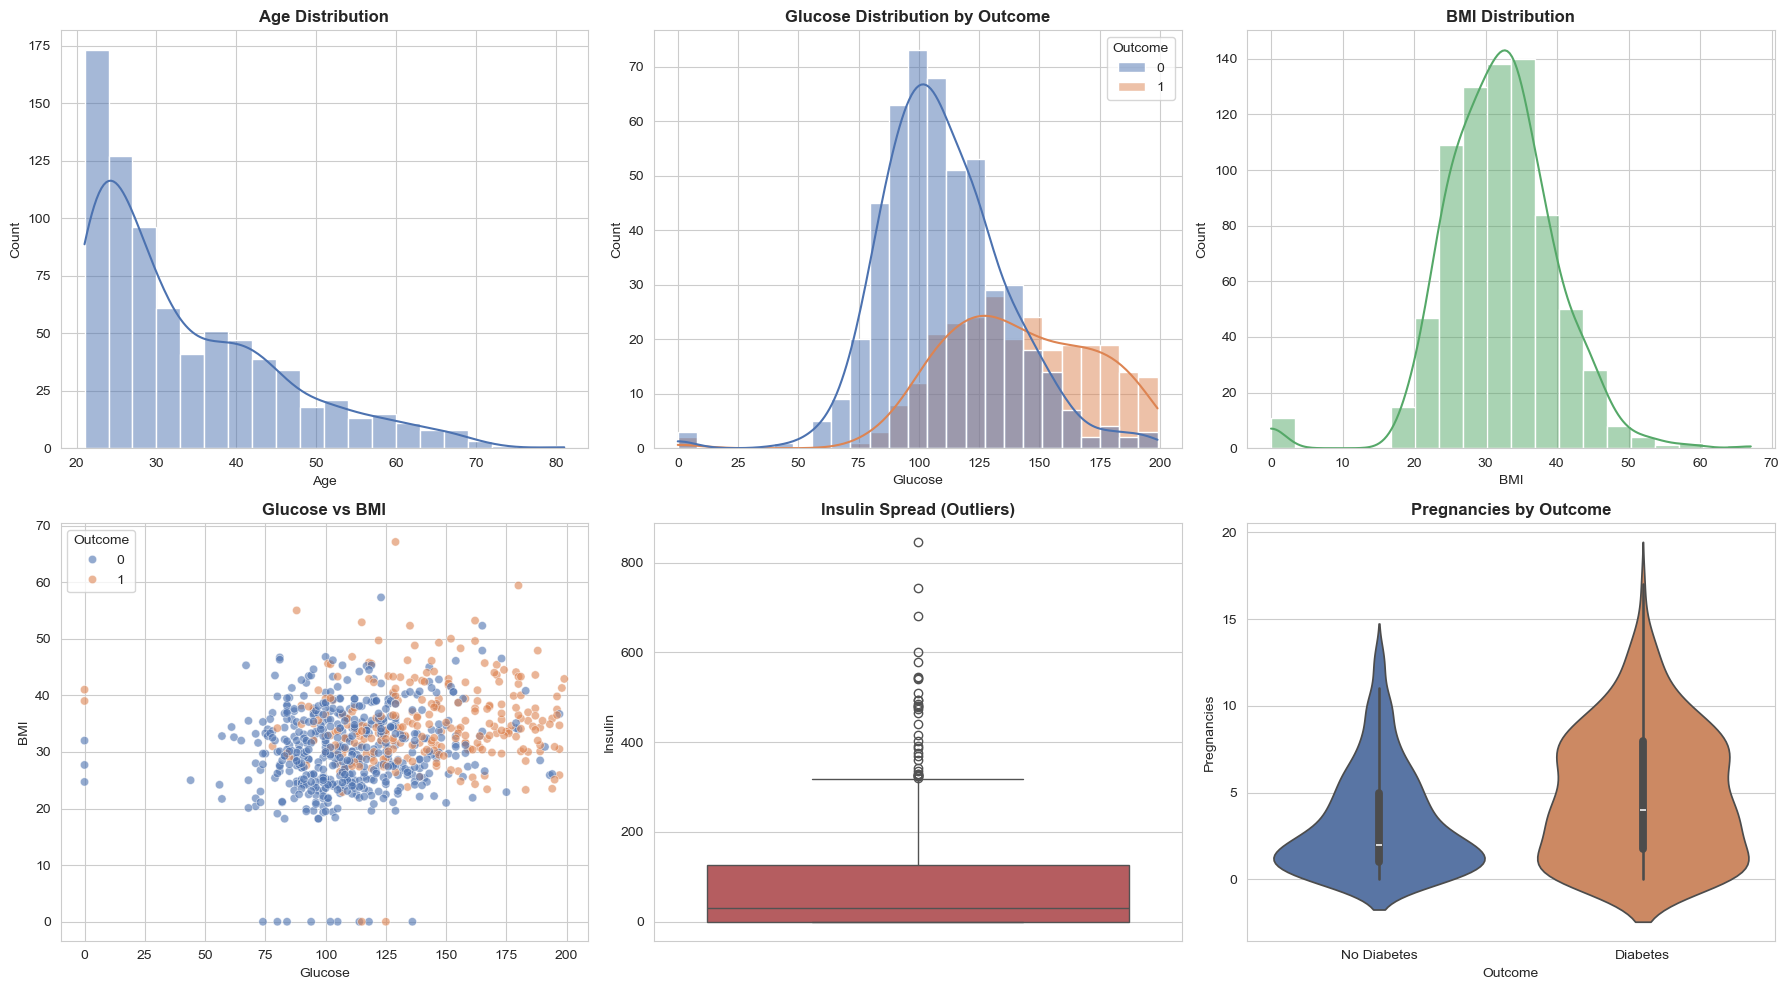

In [18]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
df = pd.read_csv('C:/Users/HP/Downloads/diabetes.csv')

fig, axes = plt.subplots(2, 3, figsize=(18,10))

# 1. Age distribution
sns.histplot(df['Age'], bins=20, kde=True, ax=axes[0,0], color='#4C72B0')
axes[0,0].set_title('Age Distribution', fontweight='bold')

# 2. Glucose distribution split by outcome
sns.histplot(data=df, x='Glucose', hue='Outcome', bins=25, kde=True, ax=axes[0,1], palette=['#4C72B0','#DD8452'])
axes[0,1].set_title('Glucose Distribution by Outcome', fontweight='bold')

# 3. BMI distribution
sns.histplot(df['BMI'], bins=20, kde=True, ax=axes[0,2], color='#55A868')
axes[0,2].set_title('BMI Distribution', fontweight='bold')

# 4. Scatter: Glucose vs BMI colored by outcome
sns.scatterplot(data=df, x='Glucose', y='BMI', hue='Outcome', alpha=0.6, ax=axes[1,0], palette=['#4C72B0','#DD8452'])
axes[1,0].set_title('Glucose vs BMI', fontweight='bold')

# 5. Insulin boxplot (outlier check)
sns.boxplot(data=df, y='Insulin', ax=axes[1,1], color='#C44E52')
axes[1,1].set_title('Insulin Spread (Outliers)', fontweight='bold')

# 6. Pregnancies by outcome
sns.violinplot(data=df, x='Outcome', y='Pregnancies', hue='Outcome', legend=False, ax=axes[1,2], palette=['#4C72B0','#DD8452'])
axes[1,2].set_xticks([0,1])
axes[1,2].set_xticklabels(['No Diabetes','Diabetes'])
axes[1,2].set_title('Pregnancies by Outcome', fontweight='bold')

plt.tight_layout()
plt.show() 

# Insights per chart:
- Age Distribution — Most patients are in their 20s-30s; the data is right-skewed (long tail toward older ages).
- Glucose by Outcome — Non-diabetic patients (blue) cluster tightly around 100; diabetic patients (orange) spread wider and shift toward 125-175.
- BMI Distribution — Roughly bell-shaped, centered around 32 — confirming the average patient in this dataset is obese.
- Glucose vs BMI Scatter — Orange (diabetic) points sit more toward the right side (higher glucose) — visually confirms glucose separates the two  groups better than BMI alone.
- Insulin Boxplot — Many points above the whisker confirm heavy outliers — a handful of patients have insulin readings far beyond the typical range.
- Pregnancies by Outcome (violin) — Diabetic patients show a wider spread and higher median pregnancies than non-diabetic patients.

# Clustering — group patients without using the Outcome label
- Find natural patient segments (e.g., "high-risk obese group", "young healthy group") using unsupervised learning:

In [19]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

features = df[['Glucose','BMI','Age','Insulin']]
scaled = StandardScaler().fit_transform(features)

kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(scaled)
print(df.groupby('Cluster')[['Glucose','BMI','Age','Outcome']].mean())

            Glucose        BMI        Age   Outcome
Cluster                                            
0        148.754491  37.957485  31.161677  0.592814
1        102.154040  29.220960  26.553030  0.156566
2        134.400000  32.487317  47.853659  0.521951


- Clustering (without using Outcome) still separated patients into clear risk groups.
- Glucose + BMI = strongest combo for high risk.
- Age alone can raise risk even without extreme glucose/BMI (see Cluster 2).

# Visualize the clusters

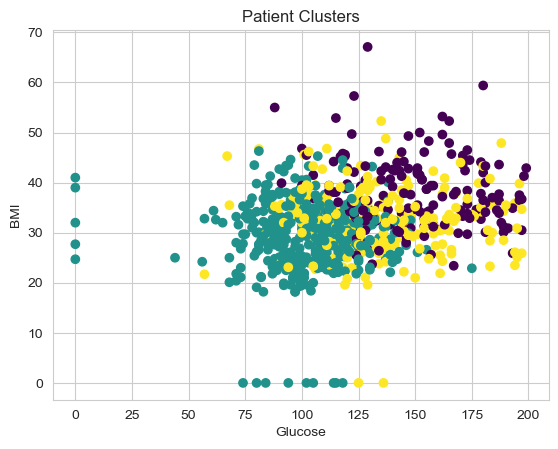

In [20]:
import matplotlib.pyplot as plt
plt.scatter(df['Glucose'], df['BMI'], c=df['Cluster'], cmap='viridis')
plt.xlabel('Glucose')
plt.ylabel('BMI')
plt.title('Patient Clusters')
plt.savefig('clusters.png')

- Teal and purple clusters are clearly separated — confirms low-risk vs high-risk grouping.
- Yellow cluster overlaps because it's mainly separated by Age, not shown in this chart.
- Dots at BMI=0 are leftover missing-data zeros, not real patients.

# Try different numbers of clusters (Elbow Method)
Check if 3 clusters is actually the best choice, or if 2 or 4 works better:

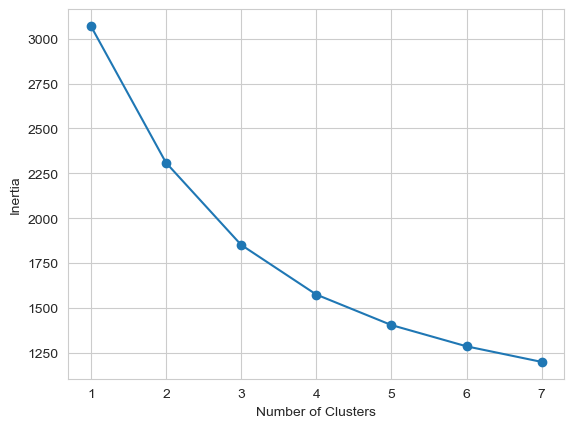

In [22]:
inertia = []
for k in range(1,8):
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(scaled)
    inertia.append(km.inertia_)  

plt.plot(range(1,8), inertia, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.savefig('elbow.png')

- The "elbow" (bend) is around k=3 — adding more clusters after that gives only small improvement.
- Confirms your earlier choice of 3 clusters was a good pick, not random.

# Name/label the clusters
Turn Cluster 0/1/2 into readable labels for your report:

In [23]:
cluster_names = {0: 'High Risk', 1: 'Low Risk', 2: 'Older Moderate Risk'}
df['RiskGroup'] = df['Cluster'].map(cluster_names)

print(df[['Cluster', 'RiskGroup']].head(10))

   Cluster            RiskGroup
0        2  Older Moderate Risk
1        1             Low Risk
2        2  Older Moderate Risk
3        1             Low Risk
4        0            High Risk
5        1             Low Risk
6        1             Low Risk
7        1             Low Risk
8        0            High Risk
9        2  Older Moderate Risk


- Most patients fall into the "Low Risk" group.
- "High Risk" is the smallest group — about 1 in 5 patients.
- Cluster numbers are now readable labels, easier to use in charts/reports.

# Build the prediction model (Logistic Regression)
Now that you understand the data well, this is the natural next big step — predict Outcome using all features:

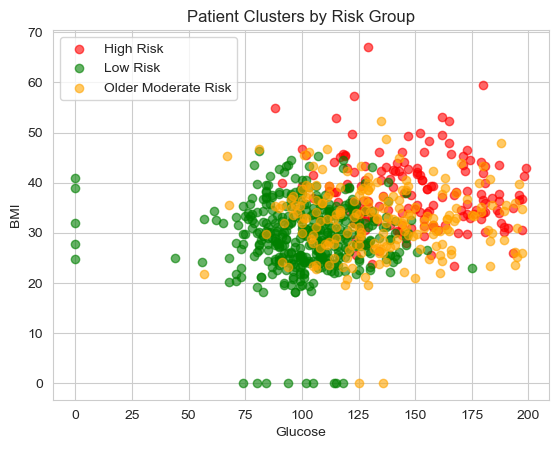

In [24]:
import matplotlib.pyplot as plt

colors = {'High Risk': 'red', 'Low Risk': 'green', 'Older Moderate Risk': 'orange'}

for group, color in colors.items():
    subset = df[df['RiskGroup'] == group]
    plt.scatter(subset['Glucose'], subset['BMI'], label=group, color=color, alpha=0.6)

plt.xlabel('Glucose')
plt.ylabel('BMI')
plt.title('Patient Clusters by Risk Group')
plt.legend()
plt.savefig('clusters_named.png')

- Legend now shows readable names instead of 0/1/2 — easier to explain in your report.
- Red and green are clearly separated; orange overlaps both, since it's mostly driven by Age (not visible in this chart).